# Test Fine-Tuned Qwen 3.5 VLM LoRA

This notebook loads the local base model and your saved LoRA adapter, then tests one sample from `train_data/vlm_val.jsonl`.

In [1]:
import torch
from pathlib import Path
from peft import PeftModel
from transformers import AutoModelForImageTextToText, AutoProcessor

BASE_MODEL_DIR = Path("models/Qwen3.5-9B")
ADAPTER_DIR = Path("outputs/qwen35-floorplan-lora/best-checkpoint")

processor = AutoProcessor.from_pretrained(ADAPTER_DIR)
processor.tokenizer.padding_side = "right"

dtype = torch.bfloat16 if (torch.cuda.is_available() and torch.cuda.is_bf16_supported()) else torch.float16

base_model = AutoModelForImageTextToText.from_pretrained(
    BASE_MODEL_DIR,
    torch_dtype=dtype,
    device_map="auto",
)

model = PeftModel.from_pretrained(base_model, ADAPTER_DIR)
model.eval()

print("Loaded base + your best LoRA checkpoint.")

./.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).
`torch_dtype` is deprecated! Use `dtype` instead!
The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d
Loading weights: 100%|██████████| 760/760 [00:05<00:00, 133.19it/s]


Loaded base + your best LoRA checkpoint.


Image: 10022.png


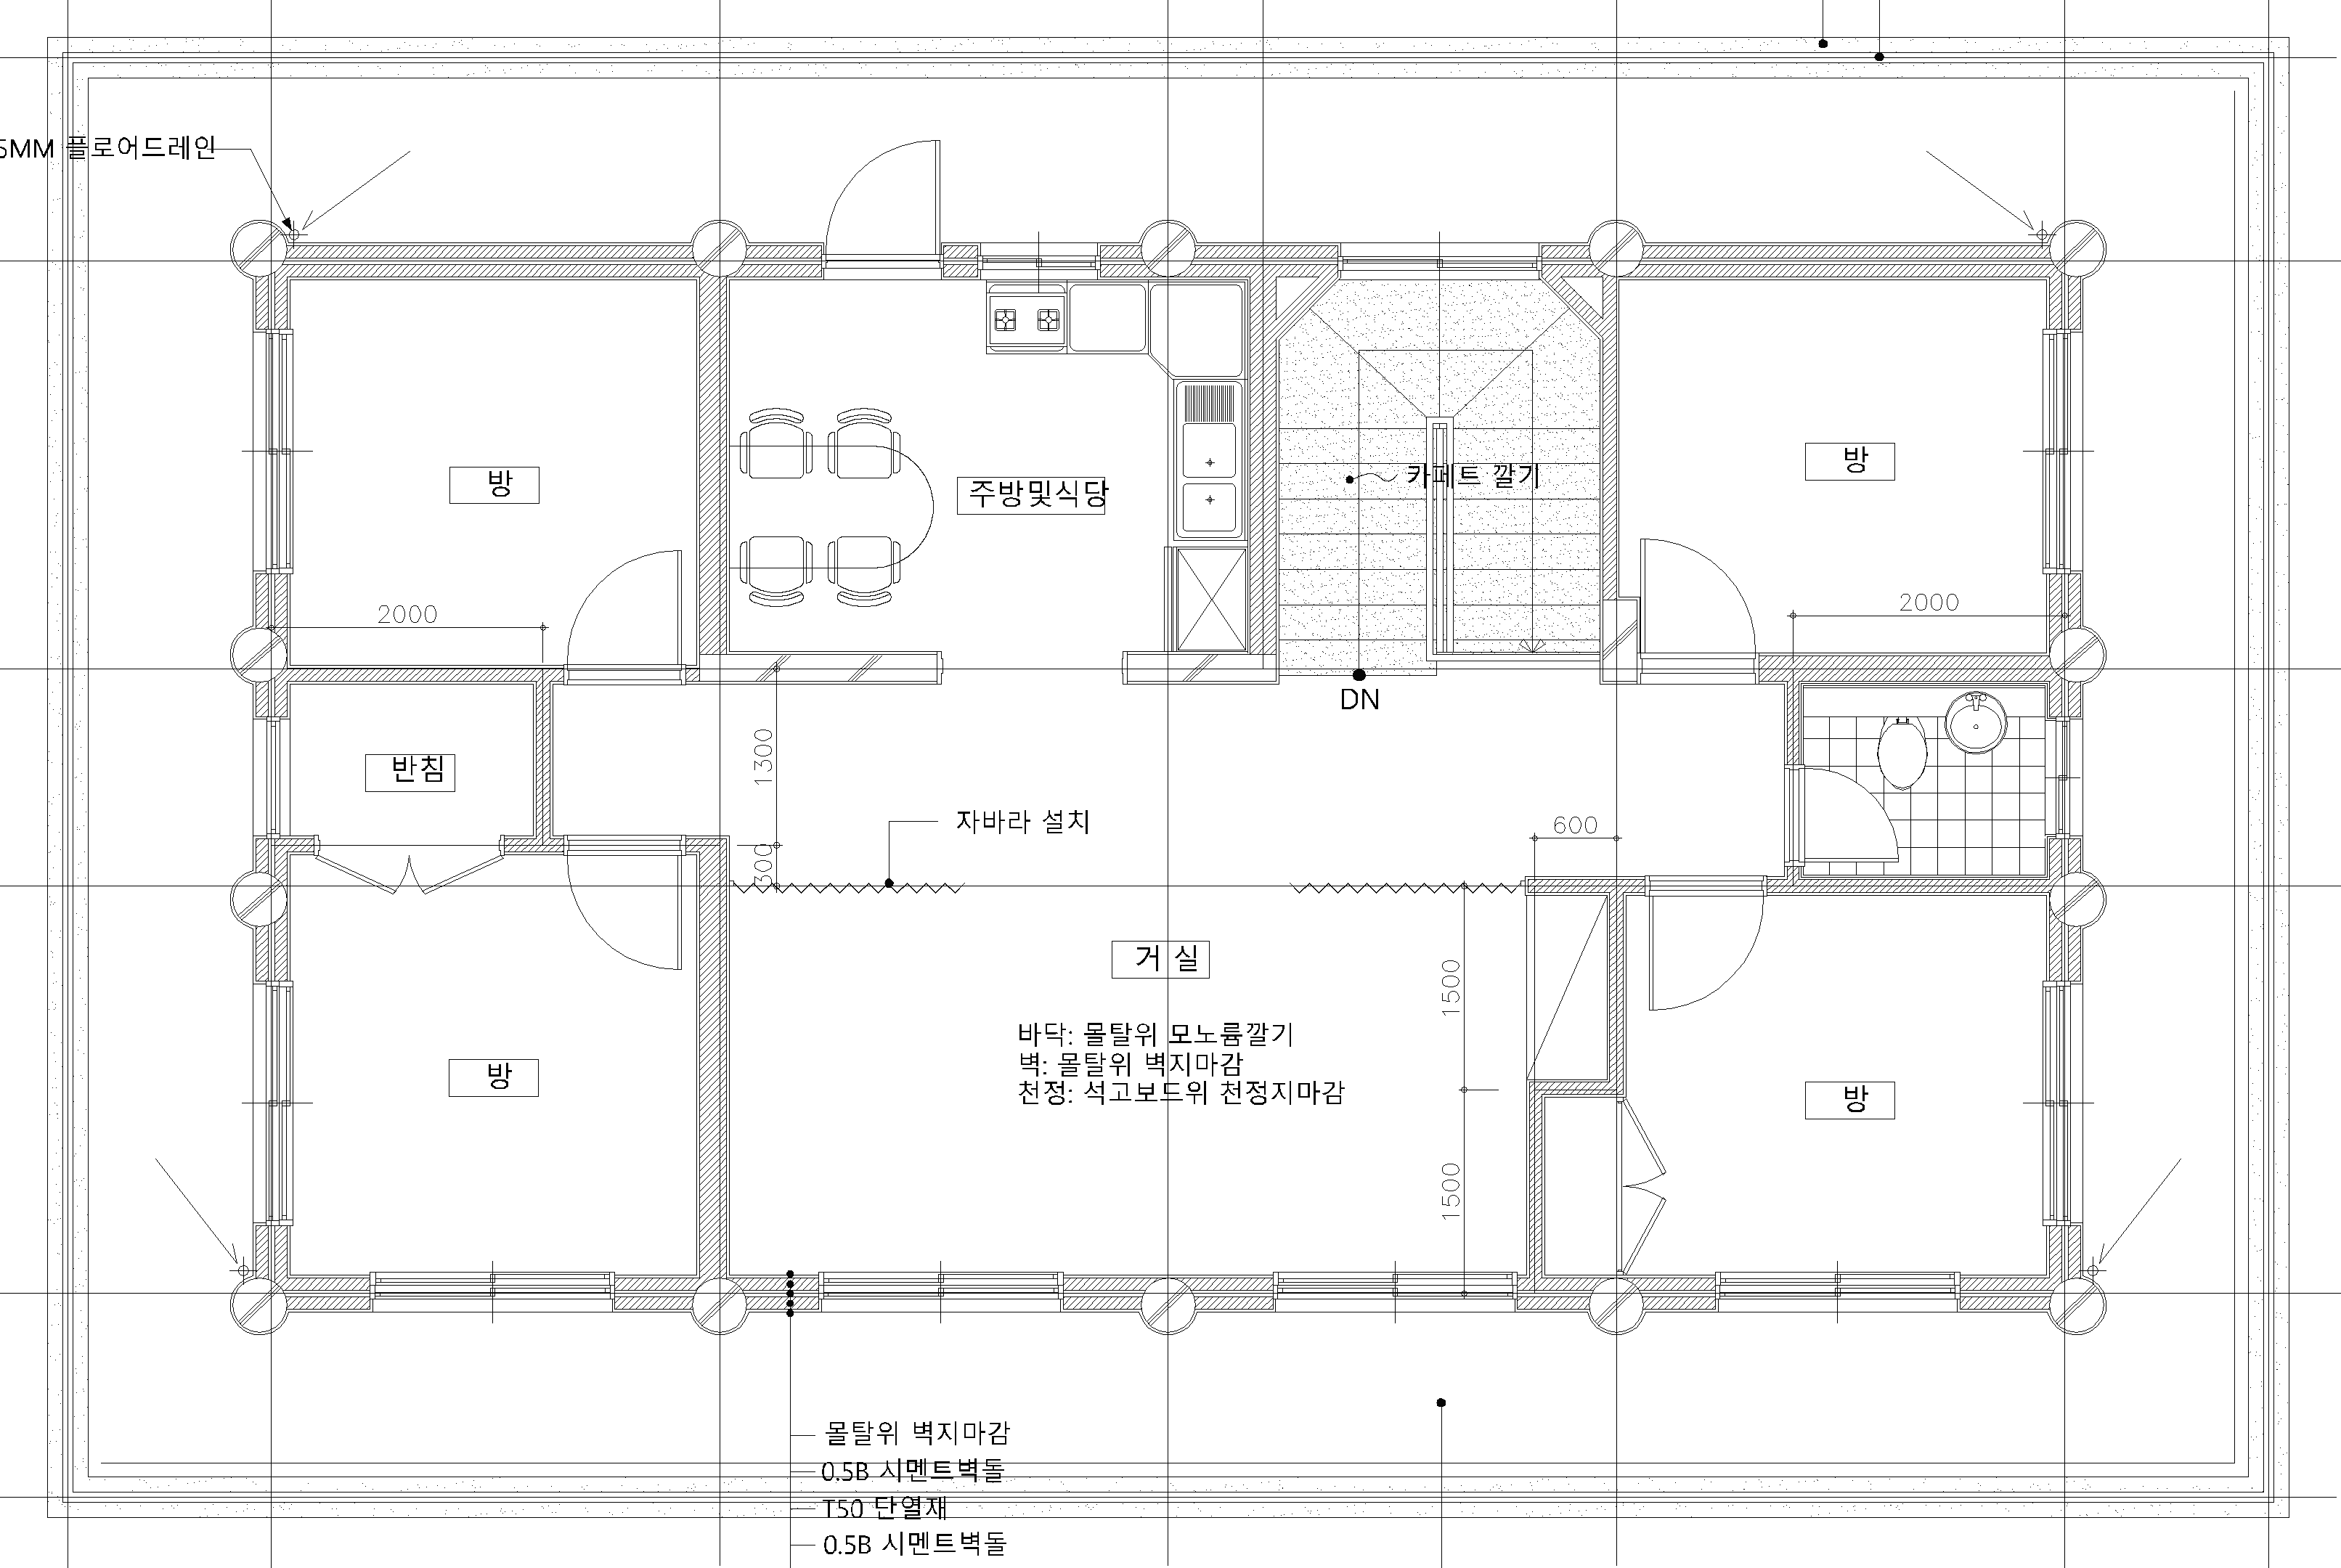

In [2]:
import random
from PIL import Image

IMAGE_DIR = Path("raw_data/images/")

# ── pick a random image ──────────────────────────────────────
image_paths = list(IMAGE_DIR.glob("*.jpg")) + list(IMAGE_DIR.glob("*.png"))
image_path  = random.choice(image_paths)
image       = Image.open(image_path).convert("RGB")

print(f"Image: {image_path.name}")
display(image)   # shows inline in Jupyter


In [3]:
import json
import re

def parse_model_output(output_text):
    text = (output_text or "").strip()

    text = re.sub(r"^```json\s*", "", text)
    text = re.sub(r"^```\s*", "", text)
    text = re.sub(r"\s*```$", "", text)
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL)
    text = text.replace("</think>", "").strip()

    start = text.find("{")
    end = text.rfind("}")
    if start == -1 or end == -1 or end <= start:
        raise ValueError("No JSON object found in model output.")

    json_text = text[start:end + 1]
    return json.loads(json_text)



In [4]:
import json
import torch

target_class = "Living room"
#question = f'identify all {target_class.lower()} and return their coordinates'
question = 'how many living room are in this floor plan? Return only JSON like {"answer":"There are N living rooms."}'

messages = [
    {
        "role": "system",
        "content": [
            {
                "type": "text",
                #"text": f'Return only valid JSON in this exact schema: {{"class":"{target_class}","count":N,"polygons":[[[x,y],[x,y],[x,y],[x,y]]],"present":true}}. No explanation. No reasoning. No bullets. No extra text.',
                "text": (
                    f'Return only valid JSON. '
                    f'Do not output analysis. '
                    f'Do not describe the image. '
                    f'Do not output numbered steps. '
                    f'Do not output bullet points. '
                    f'Do not explain your reasoning. '
                    f'Do not think step by step. '
                    f'Do not output <think> or </think>. '
                    f'Do not restate the question. '
                    f'Do not say "The user wants". '
                    f'Do not include any text before or after the JSON. '
                    f'Output exactly one JSON object and nothing else. '
                    f'If unsure, still return JSON only.'
                )

            }
        ],
    },
    {
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": question},
        ],
    },
]

text = processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

inputs = processor(
    text=[text],
    images=[[image]],
    return_tensors="pt",
    padding=True,
)

device = next(model.parameters()).device
inputs = {k: v.to(device) if hasattr(v, "to") else v for k, v in inputs.items()}

answer = None
payload = None

for max_tokens in [120, 250, 400, 700, 1000]:
    with torch.no_grad():
        ids = model.generate(
            **inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            pad_token_id=processor.tokenizer.eos_token_id,
        )

    n = inputs["input_ids"].shape[1]
    candidate = processor.batch_decode(
        ids[:, n:],
        skip_special_tokens=True,
    )[0].strip()

    try:
        payload = parse_model_output(candidate)
        answer = candidate
        print(f"Success with max_new_tokens={max_tokens}")
        break
    except (ValueError, json.JSONDecodeError):
        answer = candidate

if payload is None:
    print("Could not parse complete JSON. Last output:")

print(answer)


Success with max_new_tokens=700
The user wants to count the number of living rooms in the provided floor plan.

1.  **Analyze the image:** I need to identify walls, doors, windows, and room annotations.
2.  **Locate living rooms:** I'll look for annotations like "Living Kitchen" or "Living Room" or infer from the layout.
    *   There is a large open space in the center-right area. It has annotations for "Living Kitchen" (implied by the sink, gas, and table/chairs) and "Living Room" (implied by the large open space and "Jabalara" text). Wait, let's look closer at the annotations.
    *   Top left: "Bedroom" (방).
    *   Top right: "Bedroom" (방).
    *   Bottom left: "Bedroom" (방).
    *   Bottom right: "Bedroom" (방).
    *   Center: There is a large open area. It contains a sink, gas, and a table with chairs. This is clearly a kitchen/dining area. Next to it, there is a large open space labeled "Jabalara" (which is a type of wall, but the space itself is open). Wait, looking at the lay